# Battery State of Charge Estimation for resource constrained embedded devices
**State of charge (SOC)** is the charge level of a battery, normalised between 0 (fully discharged) and 1 (fully charged) [1].

**Data_set** 
EV Lithium Ion Battery State of Charge Dataset [2]

## References
\[1\] ‘What Is Battery State of Charge?’ Accessed: Nov. 11, 2026. [Online]. Available: https://www.mathworks.com/discovery/battery-state-of-charge.html

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from pathlib import Path

**Load Dataset**


In [6]:
project_dir = Path.cwd()
data_dir = project_dir / 'dataset'

battery_data_df = pd.read_excel(data_dir /'battery_charging_and_discharging.xlsx')
battery_data_df.head()


,Cycle_Number,Cycle_Type,Time,Ambient_Temperature,Delta t,Current_measured,Voltage_measured,Current_Mod,cummulative Ah,Ah,soc
0,1,charge,11.125,24,2.781,1.510817,4.012944,NaN,0.000754,0.001167,0.037707
1,1,charge,13.891,24,2.766,1.513170,4.018813,NaN,0.001917,0.001163,0.095838
2,1,charge,16.672,24,2.781,1.512649,4.023530,NaN,0.003085,0.001169,0.154264
3,1,charge,19.500,24,2.828,1.511927,4.028041,NaN,0.004273,0.001188,0.213649
4,1,charge,22.282,24,2.782,1.512427,4.031896,NaN,0.005442,0.001169,0.272088


In [9]:

# Dataset dimensions
print("Dataset shape:", battery_data_df.shape)

# Column information
battery_data_df.info()

# Missing values
print("\nMissing values:")
print(battery_data_df.isnull().sum())

# Statistical summary
battery_data_df.describe().T



Dataset shape: (590336, 11)
<class 'pandas.DataFrame'>
RangeIndex: 590336 entries, 0 to 590335
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Cycle_Number         590336 non-null  int64  
 1   Cycle_Type           590336 non-null  str    
 2   Time                 590336 non-null  float64
 3   Ambient_Temperature  590336 non-null  int64  
 4   Delta t              590336 non-null  float64
 5   Current_measured     590336 non-null  float64
 6   Voltage_measured     590336 non-null  float64
 7   Current_Mod          50263 non-null   float64
 8   cummulative Ah       590336 non-null  float64
 9   Ah                   590336 non-null  float64
 10  soc                  590336 non-null  float64
dtypes: float64(8), int64(2), str(1)
memory usage: 49.5 MB

Missing values:
Cycle_Number                0
Cycle_Type                  0
Time                        0
Ambient_Temperature         0
Delta t      

,count,mean,std,min,25%,50%,75%,max
Cycle_Number,590336.0,330.765811,165.297544,1.000000,192.000000,334.000000,475.000000,616.000000
Time,590336.0,4756.104552,3145.205801,0.000000,1923.496000,4456.625000,7488.156000,10807.328000
Ambient_Temperature,590336.0,24.000000,0.000000,24.000000,24.000000,24.000000,24.000000,24.000000
Delta t,590336.0,3.138765,78.324433,-10797.969000,2.734000,2.906000,2.922000,22.078000
Current_measured,590336.0,0.360001,0.884905,-4.480834,0.055677,0.186548,1.055322,1.530124
Voltage_measured,590336.0,4.104125,0.224802,-0.001422,4.153697,4.196998,4.199246,8.083344
Current_Mod,50263.0,1.773450,0.647745,-0.008809,2.008815,2.010095,2.011178,2.027018
cummulative Ah,590336.0,1.106671,0.469501,-0.018452,0.825897,1.229559,1.428245,2.018877
Ah,590336.0,0.000888,0.001634,-0.018452,0.000063,0.000239,0.001048,0.013569
soc,590336.0,56.682343,23.127252,-0.530196,43.428835,62.139946,72.239617,100.943829


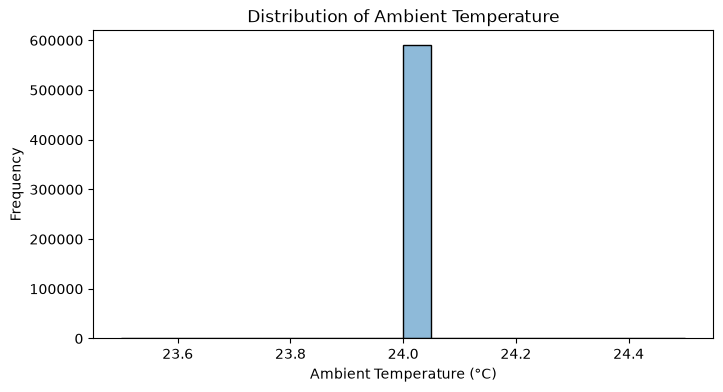

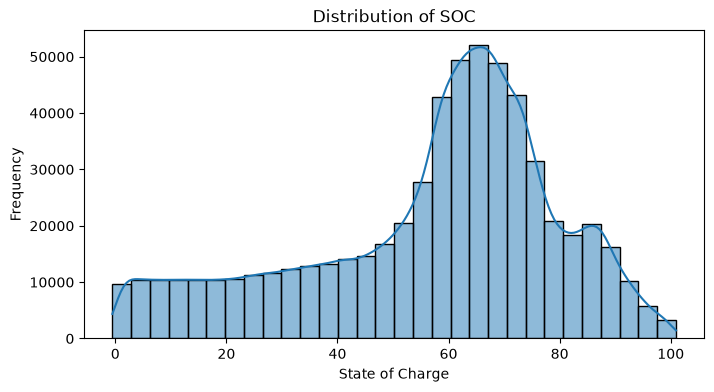

Cycle_Type
charge       540073
discharge     50263
Name: count, dtype: int64


In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of ambient temperature
plt.figure(figsize=(8, 4))
sns.histplot(battery_data_df['Ambient_Temperature'], bins=20, kde=True)
plt.xlabel('Ambient Temperature (°C)')
plt.ylabel('Frequency')
plt.title('Distribution of Ambient Temperature')
plt.show()

# SOC distribution
plt.figure(figsize=(8, 4))
sns.histplot(battery_data_df['soc'], bins=30, kde=True)
plt.xlabel('State of Charge')
plt.ylabel('Frequency')
plt.title('Distribution of SOC')
plt.show()

# Charging and discharging samples
print(battery_data_df['Cycle_Type'].value_counts())


In [11]:

# Statistical summary
display(battery_data_df.describe().T)

# Unique ambient temperatures
print("\nAmbient temperatures:")
print(sorted(battery_data_df['Ambient_Temperature'].unique()))

# Charge/discharge distribution
print("\nCycle types:")
print(battery_data_df['Cycle_Type'].value_counts())

# Number of unique cycles
print("\nNumber of cycles:")
print(battery_data_df['Cycle_Number'].nunique())

# SOC range
print("\nSOC range:")
print(battery_data_df['soc'].min(), battery_data_df['soc'].max())


,count,mean,std,min,25%,50%,75%,max
Cycle_Number,590336.0,330.765811,165.297544,1.000000,192.000000,334.000000,475.000000,616.000000
Time,590336.0,4756.104552,3145.205801,0.000000,1923.496000,4456.625000,7488.156000,10807.328000
Ambient_Temperature,590336.0,24.000000,0.000000,24.000000,24.000000,24.000000,24.000000,24.000000
Delta t,590336.0,3.138765,78.324433,-10797.969000,2.734000,2.906000,2.922000,22.078000
Current_measured,590336.0,0.360001,0.884905,-4.480834,0.055677,0.186548,1.055322,1.530124
Voltage_measured,590336.0,4.104125,0.224802,-0.001422,4.153697,4.196998,4.199246,8.083344
Current_Mod,50263.0,1.773450,0.647745,-0.008809,2.008815,2.010095,2.011178,2.027018
cummulative Ah,590336.0,1.106671,0.469501,-0.018452,0.825897,1.229559,1.428245,2.018877
Ah,590336.0,0.000888,0.001634,-0.018452,0.000063,0.000239,0.001048,0.013569
soc,590336.0,56.682343,23.127252,-0.530196,43.428835,62.139946,72.239617,100.943829



Ambient temperatures:
[np.int64(24)]

Cycle types:
Cycle_Type
charge       540073
discharge     50263
Name: count, dtype: int64

Number of cycles:
338

SOC range:
-0.5301960303962714 100.94382911976871


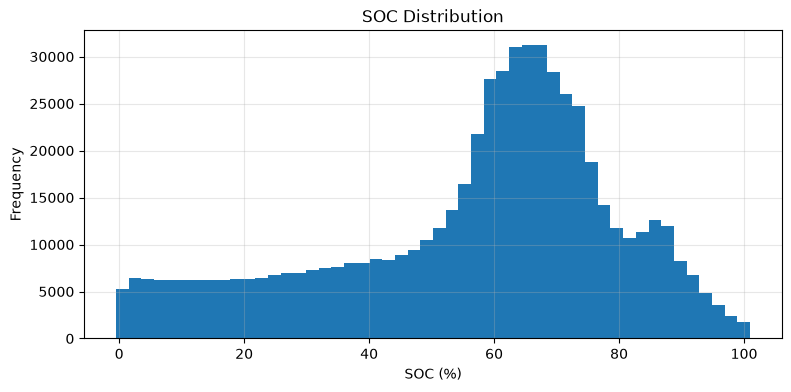

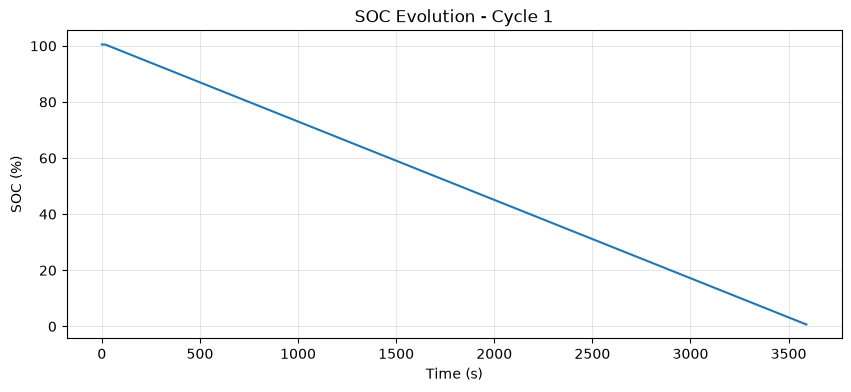

                 min         max       mean        std
Cycle_Type                                            
charge     -0.530196  100.943829  56.567078  23.001537
discharge   0.188260  100.922614  57.920861  24.403184


In [15]:



# SOC distribution
plt.figure(figsize=(9, 4))
plt.hist(battery_data_df['soc'], bins=50)
plt.xlabel('SOC (%)')
plt.ylabel('Frequency')
plt.title('SOC Distribution')
plt.grid(alpha=0.3)
plt.show()

# SOC against time for the first cycle
cycle_1 = battery_data_df[
    battery_data_df['Cycle_Number'] == 4
]

plt.figure(figsize=(10, 4))
plt.plot(cycle_1['Time'], cycle_1['soc'])
plt.xlabel('Time (s)')
plt.ylabel('SOC (%)')
plt.title('SOC Evolution - Cycle 1')
plt.grid(alpha=0.3)
plt.show()

# SOC range by cycle type
print(
    battery_data_df.groupby('Cycle_Type')['soc']
    .agg(['min', 'max', 'mean', 'std'])
)
